# 05 – kPCA biplots and final kernel comparison

**Aim.** Show, with biplots of kPC1–kPC7, what each non-linear kernel does to the picture compared with
linear PCA, and collect the final comparison of the kernels.

**Which settings.** Notebook 04 found that linear PCA already reaches 100 % balanced kNN accuracy on two
components, so the selection rule returned the linear limit of every kernel (biplots identical to
notebook 02). Here each non-linear kernel is therefore shown at its **standard default** (option B):

| Kernel | Setting | Note |
|---|---|---|
| Linear | – | = the chosen setting of every kernel in notebook 04; biplots in notebook 02 |
| Polynomial | d = 2 (γ = 1/p, c = 1) | standard non-linear default |
| Gaussian | σ = median distance between samples | standard default (median heuristic) |
| Cauchy | σ = median distance between samples | standard default |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
X = X_raw[:, np.setdiff1d(np.arange(X_raw.shape[1]), kt.constant_columns(X_raw))]   # same as notebook 01
Z, mu, sigma = kt.zscore(X)
short = np.array(kt.SHORT_NAMES)
sig = kt.median_distance(Z)
print("Z:", Z.shape, f"  median distance sigma = {sig:.3f}")

Z: (92, 51)   median distance sigma = 7.747


## 1. Arrows for kPCA

A kPC is a direction in the kernel's feature space, so there are no loadings. As arrows we use the
**correlation of each variable with each kPC score**,

$$r_{jk} = \operatorname{corr}(z_j, t_k),$$

drawn with the correlation circle (radius = correlation 1) exactly as the correlation biplots of
notebook 02. For the linear kernel this equals $p_{jk}\sqrt{\lambda_k}$, so linear and kernel biplots
can be read the same way.

**Limitation.** A correlation measures only a straight-line relationship. A non-linear kPC can depend
strongly on a variable in a curved (e.g. U-shaped) way and still give a short arrow. In kPCA biplots a
short arrow therefore means "no straight-line relationship with this kPC", not "unrelated".

In [2]:
KERNELS = {   # name: (arguments for kt.kernel_matrix on the full data, arguments for the CV in notebook 04)
    "Linear":   (dict(kind="linear"),             dict(kind="linear")),
    "Poly d=2": (dict(kind="poly", degree=2),     dict(kind="poly", degree=2)),
    "Gaussian": (dict(kind="rbf", sigma=sig),     dict(kind="rbf", factor=1.0)),
    "Cauchy":   (dict(kind="cauchy", sigma=sig),  dict(kind="cauchy", factor=1.0)),
}
FILE_TAG = {"Poly d=2": "poly2", "Gaussian": "gaussian", "Cauchy": "cauchy"}

res = {}
for name, (kargs, _) in KERNELS.items():
    T, lam, evr, _ = kt.kpca(kt.kernel_matrix(Z, **kargs))
    res[name] = dict(T=T, evr=evr, R=kt.correlation_loadings(Z, T))
print("kPCA done for:", ", ".join(res))

kPCA done for: Linear, Poly d=2, Gaussian, Cauchy


## 2. Checks

In [3]:
# (a) for the linear kernel, correlation arrows = p * sqrt(lambda) of notebook 02 (up to sign)
T_pca, P_pca, lam_pca, _ = kt.pca(Z)
assert np.allclose(np.abs(res["Linear"]["R"][:, :10]), np.abs((P_pca * np.sqrt(lam_pca))[:, :10]))

# (b) correlation_loadings equals np.corrcoef
R = res["Gaussian"]["R"]
assert np.allclose(R[:, :3], [[np.corrcoef(Z[:, j], res["Gaussian"]["T"][:, k])[0, 1] for k in range(3)]
                              for j in range(Z.shape[1])])

# (c) explained variance of kPC1 matches notebook 03
assert [round(100 * res[k]["evr"][0], 1) for k in res] == [43.4, 50.2, 39.2, 31.3]
print("All checks passed.")

All checks passed.


## 3. Key comparison: kPC1–kPC2 biplots of all four kernels
The 15 variables with the longest correlation arrow in this plane are drawn. Linear PCA (top left) is the
reference.

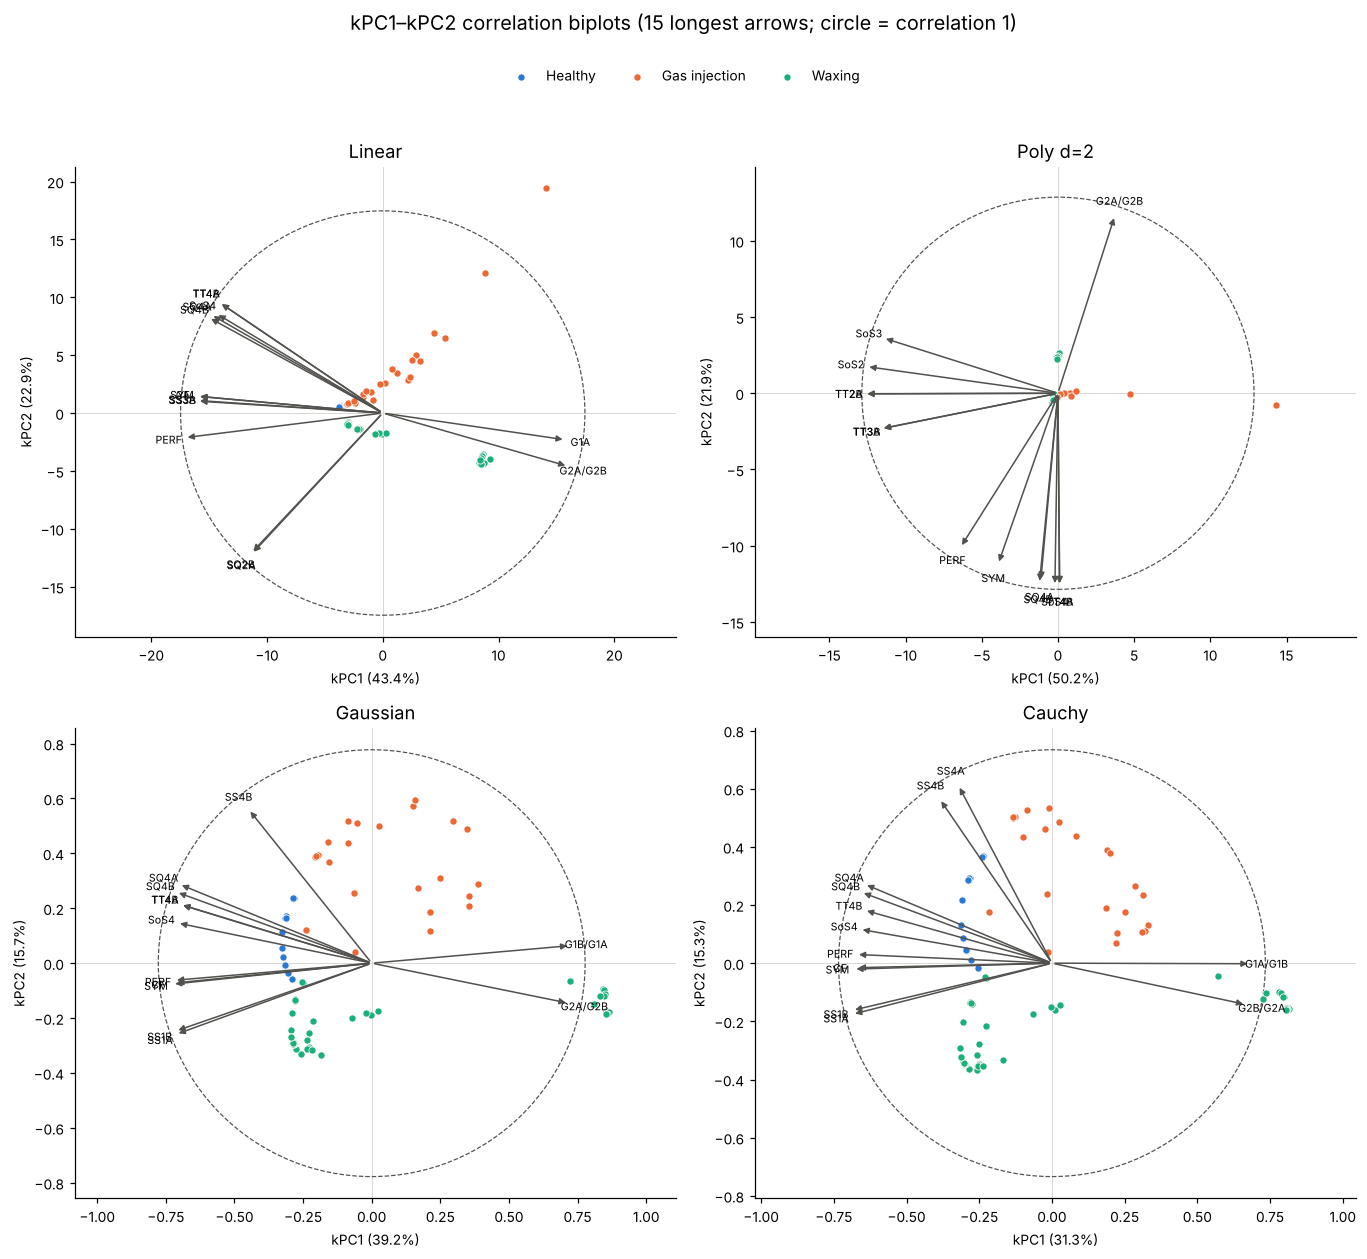

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 11.5))
for ax, (name, r) in zip(axes.flat, res.items()):
    kt.biplot(ax, r["T"], r["R"], y, short, pcs=(0, 1), n_arrows=15, circle=True, evr=r["evr"], prefix="kPC")
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(name, fontsize=12)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.955))
fig.suptitle("kPC1–kPC2 correlation biplots (15 longest arrows; circle = correlation 1)", fontsize=13, y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(f"{FIG_DIR}/m5_biplots_kpc12_comparison.png")
plt.show()

## 4. Poly d=2: kPC1–kPC7
Score matrix of all 21 pairs, then correlation biplots of kPC1–2, kPC2–3, …, kPC6–7.

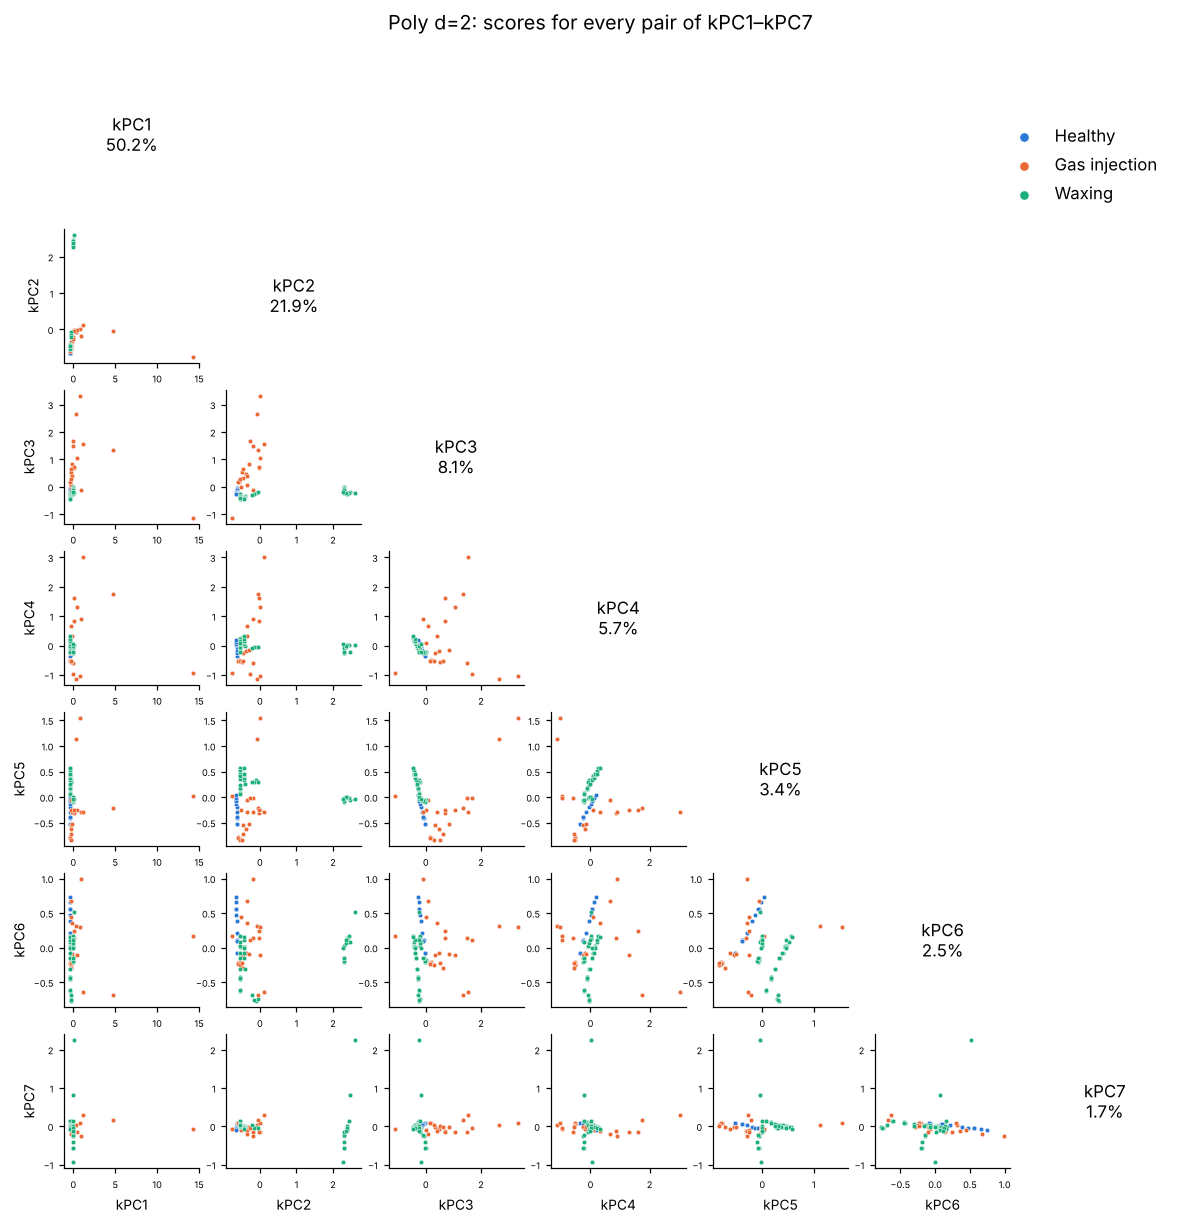

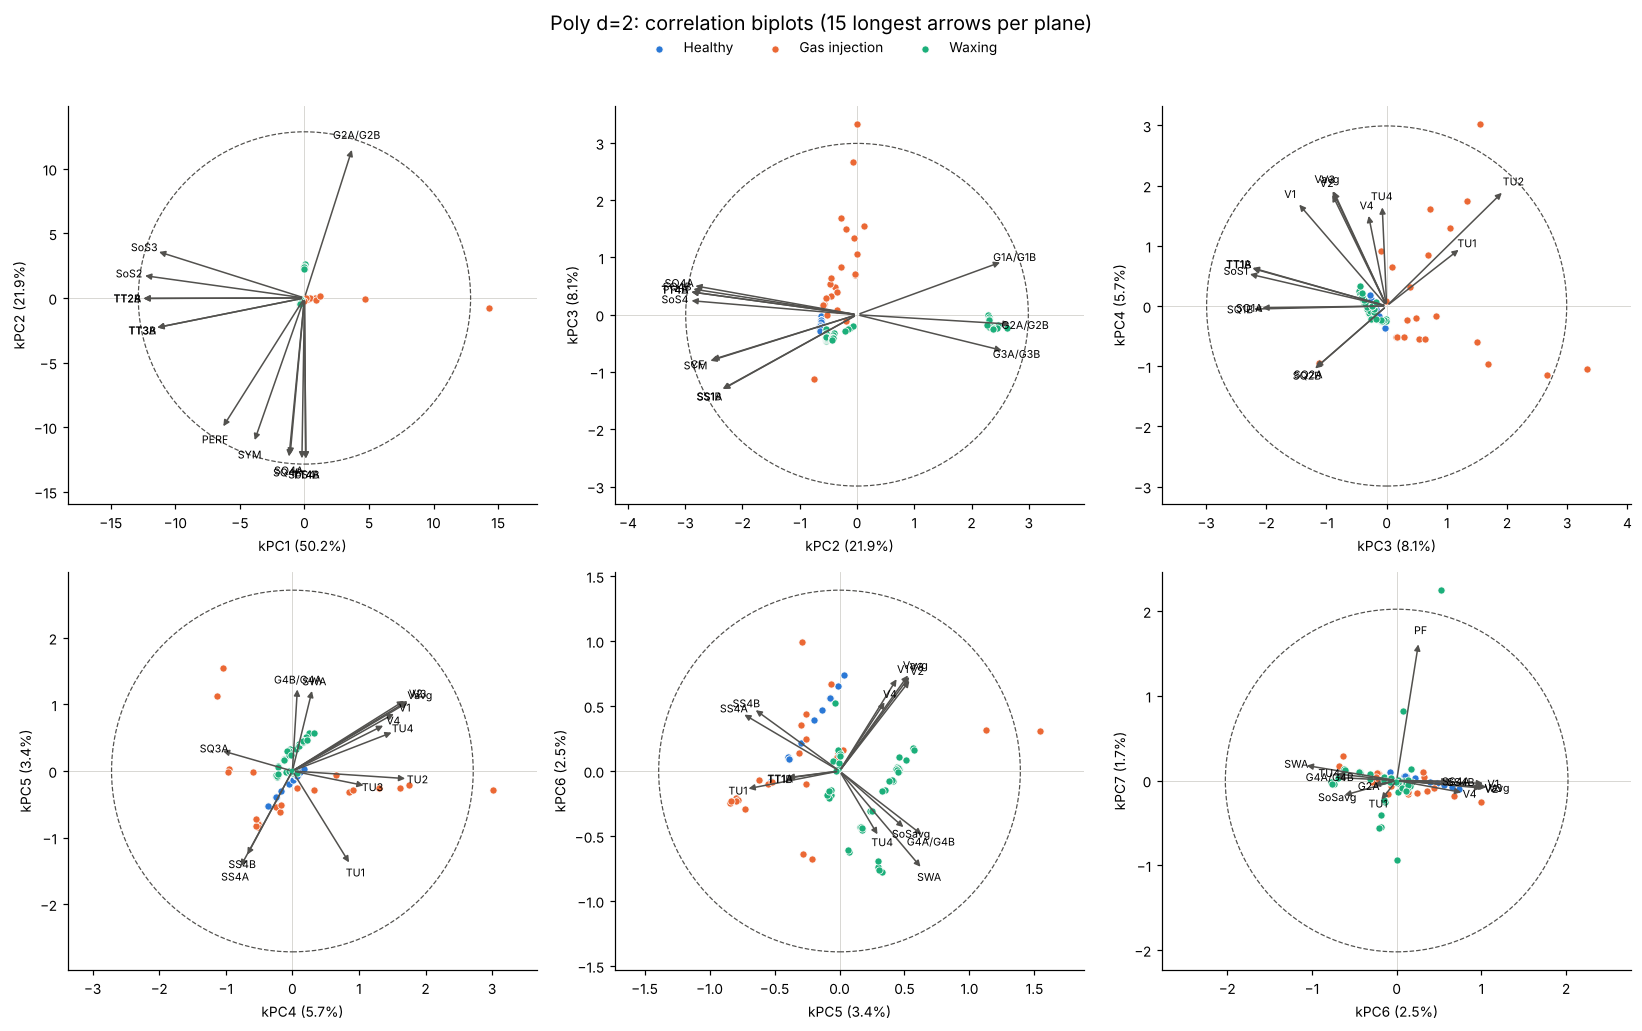

In [5]:
r = res["Poly d=2"]
fig = kt.score_matrix(r["T"], y, r["evr"], prefix="kPC", title="Poly d=2: scores for every pair of kPC1–kPC7")
fig.savefig(f"{FIG_DIR}/m5_poly2_scores_matrix.png", bbox_inches="tight")
plt.show()

fig = kt.biplot_grid(r["T"], r["R"], y, short, r["evr"], circle=True, prefix="kPC",
                     title="Poly d=2: correlation biplots (15 longest arrows per plane)")
fig.savefig(f"{FIG_DIR}/m5_poly2_biplots.png")
plt.show()

## 5. Gaussian: kPC1–kPC7
Score matrix of all 21 pairs, then correlation biplots of kPC1–2, kPC2–3, …, kPC6–7.

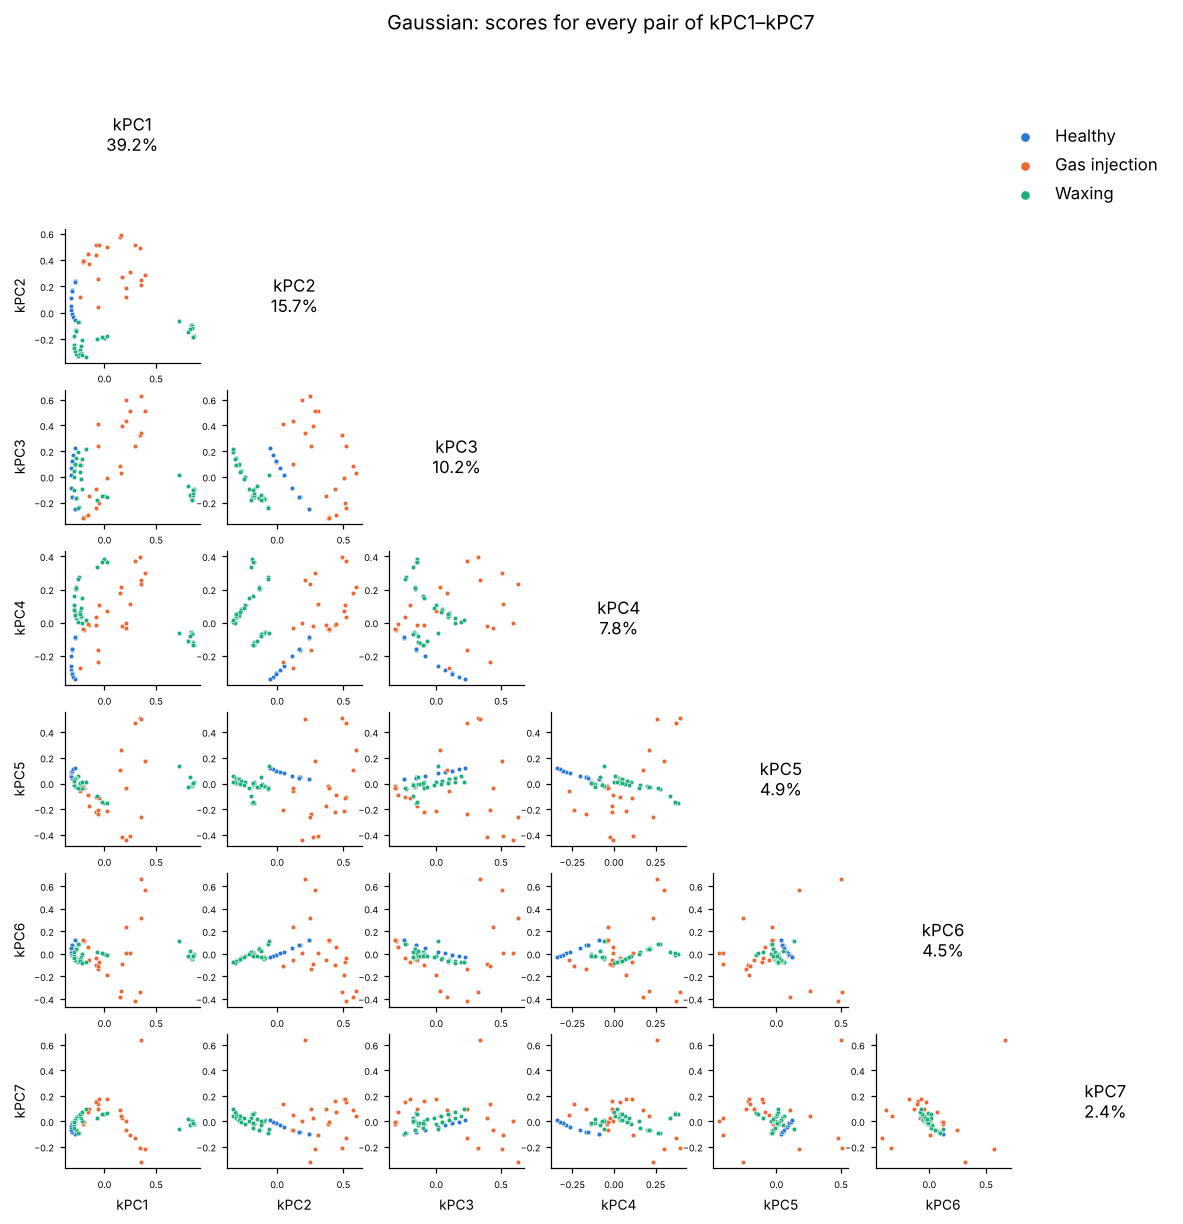

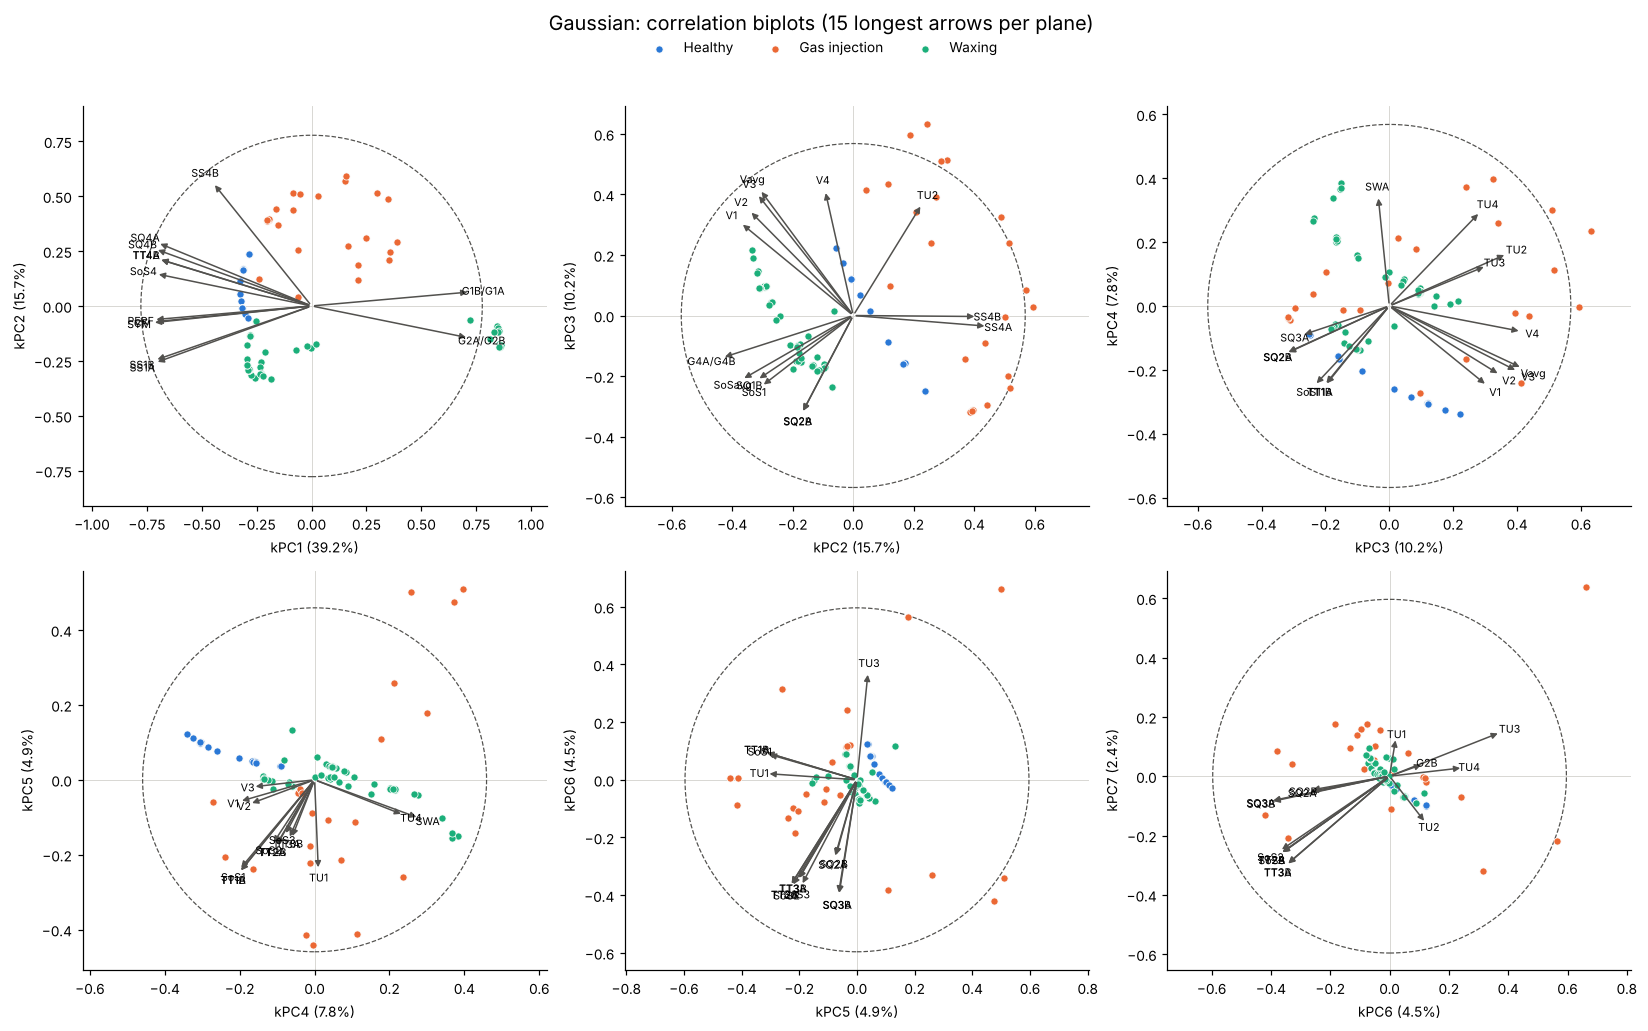

In [6]:
r = res["Gaussian"]
fig = kt.score_matrix(r["T"], y, r["evr"], prefix="kPC", title="Gaussian: scores for every pair of kPC1–kPC7")
fig.savefig(f"{FIG_DIR}/m5_gaussian_scores_matrix.png", bbox_inches="tight")
plt.show()

fig = kt.biplot_grid(r["T"], r["R"], y, short, r["evr"], circle=True, prefix="kPC",
                     title="Gaussian: correlation biplots (15 longest arrows per plane)")
fig.savefig(f"{FIG_DIR}/m5_gaussian_biplots.png")
plt.show()

## 6. Cauchy: kPC1–kPC7
Score matrix of all 21 pairs, then correlation biplots of kPC1–2, kPC2–3, …, kPC6–7.

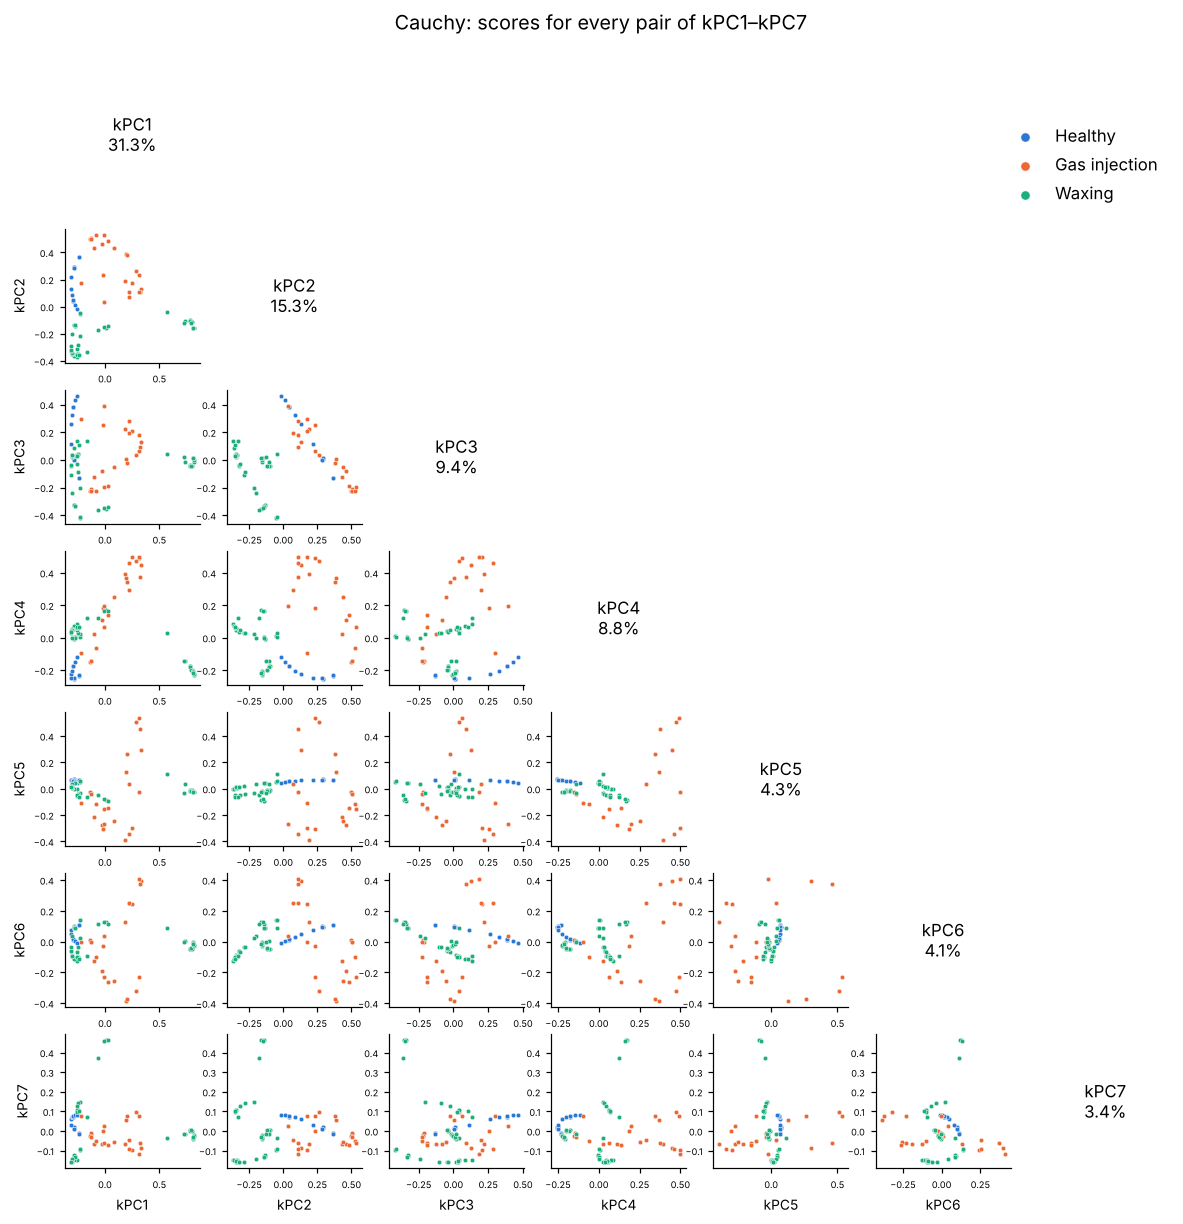

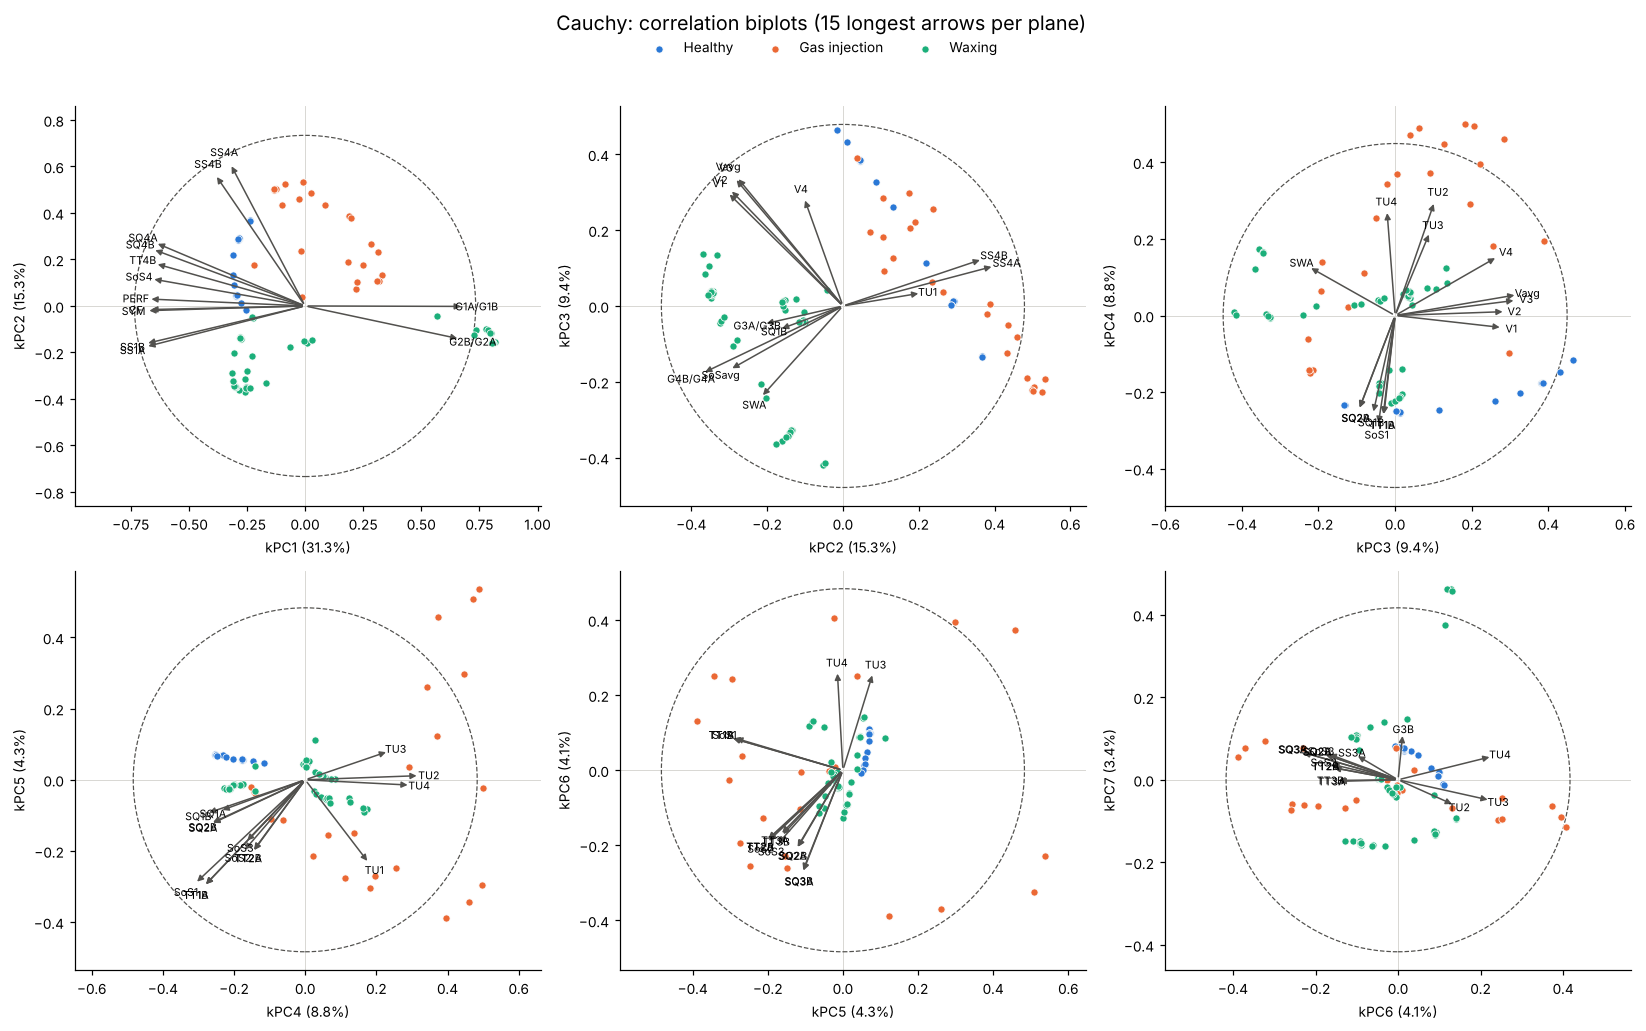

In [7]:
r = res["Cauchy"]
fig = kt.score_matrix(r["T"], y, r["evr"], prefix="kPC", title="Cauchy: scores for every pair of kPC1–kPC7")
fig.savefig(f"{FIG_DIR}/m5_cauchy_scores_matrix.png", bbox_inches="tight")
plt.show()

fig = kt.biplot_grid(r["T"], r["R"], y, short, r["evr"], circle=True, prefix="kPC",
                     title="Cauchy: correlation biplots (15 longest arrows per plane)")
fig.savefig(f"{FIG_DIR}/m5_cauchy_biplots.png")
plt.show()

## 7. What drives each kPC?
The five variables most correlated with kPC1–kPC3 for each kernel (sign shows the direction).

In [8]:
for name, r in res.items():
    print(name)
    for k in range(3):
        top = np.argsort(-np.abs(r["R"][:, k]))[:5]
        print(f"  kPC{k + 1}: " + ", ".join(f"{short[j]} ({r['R'][j, k]:+.2f})" for j in top))

Linear
  kPC1: PERF (-0.98), SYM (-0.92), SS3A (-0.92), G2B (+0.92), G2A (+0.92)
  kPC2: SoS3 (-0.79), SoS2 (-0.78), SoSavg (-0.73), SoS1 (-0.71), TU3 (+0.71)
  kPC3: Vavg (-0.83), V1 (-0.82), V3 (-0.80), V2 (-0.73), V4 (-0.60)
Poly d=2
  kPC1: TT2B (-0.99), TT2A (-0.99), SoS2 (-0.98), TT3A (-0.90), TT3B (-0.90)
  kPC2: TT4A (-0.98), TT4B (-0.98), SoS4 (-0.98), SQ4B (-0.97), SQ4A (-0.96)
  kPC3: SoS1 (-0.78), TT1A (-0.76), TT1B (-0.76), SQ1B (-0.75), SQ1A (-0.71)
Gaussian
  kPC1: SYM (-0.94), G1A (+0.93), G1B (+0.93), PERF (-0.93), CF (-0.93)
  kPC2: SS4A (+0.78), G4B (-0.76), G4A (-0.76), SS4B (+0.72), V1 (-0.66)
  kPC3: Vavg (+0.73), V4 (+0.73), V3 (+0.71), TU2 (+0.65), V2 (+0.61)
Cauchy
  kPC1: SS1B (-0.94), SS1A (-0.94), G1B (+0.93), G1A (+0.93), SYM (-0.93)
  kPC2: SS4A (+0.83), G4B (-0.77), G4A (-0.77), SS4B (+0.77), V1 (-0.64)
  kPC3: Vavg (+0.71), V3 (+0.71), V2 (+0.64), V1 (+0.63), V4 (+0.60)


## 8. Accuracy and confusion matrices for these settings
Same cross-validation as notebook 04 (balanced kNN accuracy, k = 5, repeated stratified 5-fold, 10 repeats,
everything refitted per fold, same seed). Confusion matrices for q = 2, summed over the 50 train/test splits (5 folds × 10 repeats), so
each sample is counted 10 times. As in notebook 04, the standard errors treat the 50 split scores as
independent and therefore understate the uncertainty somewhat.

kernel                q = 2            q = 3            q = 7
Linear          1.000 ± 0.000      0.972 ± 0.005      0.978 ± 0.005
Poly d=2        0.918 ± 0.012      0.979 ± 0.005      0.972 ± 0.005
Gaussian        0.964 ± 0.006      0.980 ± 0.005      0.978 ± 0.005
Cauchy          0.960 ± 0.006      0.974 ± 0.005      0.981 ± 0.004


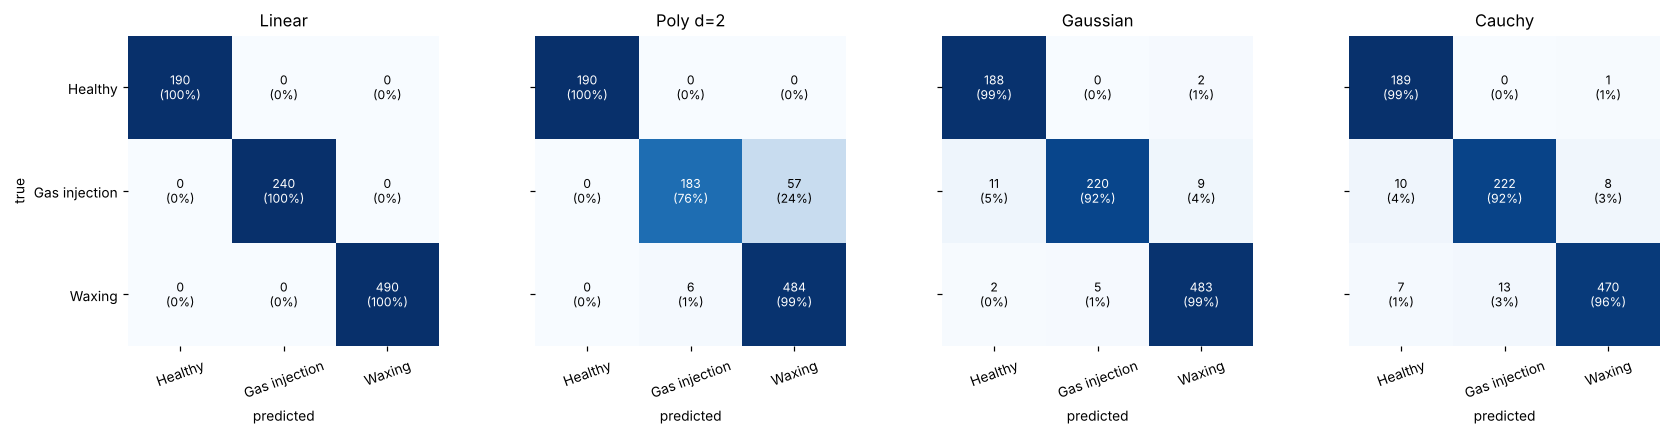

In [9]:
Q = (2, 3, 7)
acc, conf = {}, {}
for name, (_, cvargs) in KERNELS.items():
    s, c = kt.cv_balanced_accuracy(X, y, **cvargs, n_comp=Q)
    acc[name] = {q: (s[q].mean(), s[q].std(ddof=1) / np.sqrt(len(s[q]))) for q in Q}
    conf[name] = c[2]

# same values as the notebook 04 table
assert [round(acc[k][2][0], 3) for k in acc] == [1.000, 0.918, 0.964, 0.960]

print(f"{'kernel':<10}" + "".join(f"{'q = ' + str(q):>17}" for q in Q))
for name in acc:
    print(f"{name:<10}" + "".join(f"{acc[name][q][0]:>11.3f} ± {acc[name][q][1]:.3f}" for q in Q))

names = [kt.CLASS_NAMES[c] for c in kt.CLASS_NAMES]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, C) in zip(axes, conf.items()):
    share = C / C.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{C[i, j]}\n({share[i, j]:.0%})", ha="center", va="center", fontsize=8,
                    color="white" if share[i, j] > 0.6 else "black")
    ax.set_xticks(range(3), names, rotation=20)
    ax.set_yticks(range(3), names if ax is axes[0] else [])
    ax.set_xlabel("predicted")
    ax.set_title(name)
    ax.spines[:].set_visible(False)
axes[0].set_ylabel("true")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m5_confusion_defaults.png")
plt.show()

## 9. Final comparison table

In [10]:
setting = {"Linear": "–", "Poly d=2": "d = 2", "Gaussian": f"σ = {sig:.2f}", "Cauchy": f"σ = {sig:.2f}"}
print(f"{'kernel':<10}{'setting':>11}{'acc q=2':>9}{'acc q=3':>9}{'acc q=7':>9}{'var kPC1-2':>12}")
for name in res:
    print(f"{name:<10}{setting[name]:>11}" + "".join(f"{acc[name][q][0]:9.3f}" for q in Q)
          + f"{100 * res[name]['evr'][:2].sum():11.1f}%")

kernel        setting  acc q=2  acc q=3  acc q=7  var kPC1-2
Linear              –    1.000    0.972    0.978       66.3%
Poly d=2        d = 2    0.918    0.979    0.972       72.0%
Gaussian     σ = 7.75    0.964    0.980    0.978       54.9%
Cauchy       σ = 7.75    0.960    0.974    0.981       46.7%


## 10. Interpretation

**Checks.** The linear-kernel correlation arrows equal $p\sqrt{\lambda}$ from notebook 02, the correlation
function matches `np.corrcoef`, and the explained variance and accuracies reproduce notebooks 03 and 04.

**What drives the kPCs (section 7).**
- **Linear:** kPC1 = overall signal health (meter performance, symmetry, signal strength vs. gain);
  kPC2 = speed of sound vs. path-3 turbulence; kPC3 = flow velocities (operating point).
- **Gaussian and Cauchy:** kPC1 is again signal health (symmetry, crossflow, performance, path-1 signal
  strength vs. path-1 gain) and is dominated by the path-4 dropout cluster. **kPC2 changes meaning:** it
  becomes path-4 signal strength against path-4 gain, which is exactly the waxing signature found in
  notebook 01 (waxing raises G4 and lowers SS4). kPC3 is again the flow velocity. So the local kernels
  reorder the directions so that the second component is a direct waxing indicator.
- **Polynomial d = 2:** kPC1 is transit time and speed of sound on path 2 (the direction of increasing
  gas-injection severity), kPC2 is path-4 transit time, speed of sound and signal quality (the dropout
  cluster). kPC1's variance comes almost entirely from sample 31 (notebook 03), and some of its arrows are
  inflated by that single sample: without it, the correlation of SoS3 with kPC1 drops from −0.89 to −0.53
  (TT2B stays at −0.95).

**Biplots (sections 3–6).**
- **Linear (reference):** the three classes are separated in kPC1–kPC2; healthy is almost a single point
  next to the start of the gas-injection line, waxing is split into two groups.
- **Gaussian and Cauchy:** the picture keeps the same three-way layout, but with different shapes: the
  dropout cluster sits alone on the far right of kPC1, healthy forms a short curve on the left, gas
  injection spreads into a broad arc above (positive kPC2) and the other waxing samples lie below
  (negative kPC2). The classes are spread more evenly over the plane, but the gap between healthy and the
  mildest gas-injection samples is no larger than in linear PCA, and a few gas samples sit close to the
  healthy curve. The higher kPCs (4–7) mainly separate individual gas-injection samples from each other.
- **Polynomial d = 2:** almost all samples are squeezed near the origin of kPC1–kPC2, because one sample
  dominates kPC1 and the dropout cluster dominates kPC2. The healthy, mild gas-injection and non-dropout
  waxing samples are hard to tell apart in this plane.

**Accuracy and errors (section 8).** On two components the linear kernel makes no errors. The Gaussian
and Cauchy kernels misclassify mainly **gas injection as healthy** (11 and 10 of 240 test predictions)
or as waxing (9 and 8); Cauchy also confuses some waxing samples (20 of 490). The polynomial kernel
misclassifies 24 % of the gas-injection predictions as waxing. With 3 or 7 components all four kernels
reach 0.97–0.98, within about two standard errors of each other, i.e. equal within uncertainty.

## Summary – answers carried into the report
1. **Can kPCA distinguish the three states?** Yes. With every kernel, healthy, gas injection and waxing
   occupy different regions of the first few kPCs (balanced kNN accuracy 0.97–0.98 on 3 kPCs for all
   kernels). But this is not a merit of the kernels: linear PCA already separates them perfectly on two
   components.
2. **Which kernel is most appropriate?** By the agreed criterion (balanced kNN accuracy), the **linear
   kernel**, or equivalently a Gaussian or Cauchy kernel with a very large width (notebook 04). Among the
   non-linear defaults, **Gaussian and Cauchy** behave similarly and are clearly better than the
   **polynomial** kernel, which is dominated by one extreme sample. Gaussian and Cauchy offer a different,
   physically readable view (kPC2 = waxing signature), at the cost of a few healthy/gas confusions on two
   components.
3. The critical boundary for every method is **healthy vs. mild gas injection**.
